DATA SCIENCE PROJECT


Medical Cost prediction

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error , mean_squared_error

import joblib

In [3]:
import warnings 
warnings.filterwarnings("ignore")

In [4]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

pd.set_option("display.max_columns",None)

Read CSV file

In [5]:
df = pd.read_csv("medical_insurance.csv")

In [6]:
df.shape

(2772, 7)

In [7]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   object 
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   object 
 5   region    2772 non-null   object 
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 151.7+ KB


In [9]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [10]:
df.describe()

,age,bmi,children,charges
count,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,30.701349,1.101732,13261.369959
std,14.081459,6.129449,1.214806,12151.768945
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,26.220000,0.000000,4687.797000
50%,39.000000,30.447500,1.000000,9333.014350
75%,51.000000,34.770000,2.000000,16577.779500
max,64.000000,53.130000,5.000000,63770.428010


Duplicates record

In [11]:
print(df.duplicated().sum())

1435


In [12]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


combine duplicate record like how many time it duplicate?


In [13]:
dup_counts = df.groupby(list(df.columns)).size().reset_index(name = "count")

In [14]:
dup_counts["count"].value_counts().sort_index()

count
2    1288
4      49
Name: count, dtype: int64

excalty 1288 rows 2 times copy and 49 rows 4 times copy

In [15]:
df = df.drop_duplicates().reset_index(drop = True)

In [16]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1332,50,male,30.970,3,no,northwest,10600.54830
1333,18,female,31.920,0,no,northeast,2205.98080
1334,18,female,36.850,0,no,southeast,1629.83350
1335,21,female,25.800,0,no,southwest,2007.94500


Columns in Dataset

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1337 entries, 0 to 1336
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   object 
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   object 
 5   region    1337 non-null   object 
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.2+ KB


In [18]:
# Now categorical variables (sex , smoker , region)

for col in ["sex", "smoker", "region"]:
    print(f"-------{col}----")
    print(df[col].value_counts())
    print(df[col].value_counts(normalize = True).round(3))

-------sex----
sex
male      675
female    662
Name: count, dtype: int64
sex
male      0.505
female    0.495
Name: proportion, dtype: float64
-------smoker----
smoker
no     1063
yes     274
Name: count, dtype: int64
smoker
no     0.795
yes    0.205
Name: proportion, dtype: float64
-------region----
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
region
southeast    0.272
southwest    0.243
northwest    0.242
northeast    0.242
Name: proportion, dtype: float64


In [19]:
# check numberical variable skewed or normal dist.

for col in ["age", "bmi", "children", "charges"]:
    print(f"{col}: skew = {df[col].skew():.3f},kurtosis = {df[col].kurt():.3f}")

age: skew = 0.055,kurtosis = -1.244
bmi: skew = 0.284,kurtosis = -0.053
children: skew = 0.937,kurtosis = 0.201
charges: skew = 1.515,kurtosis = 1.604


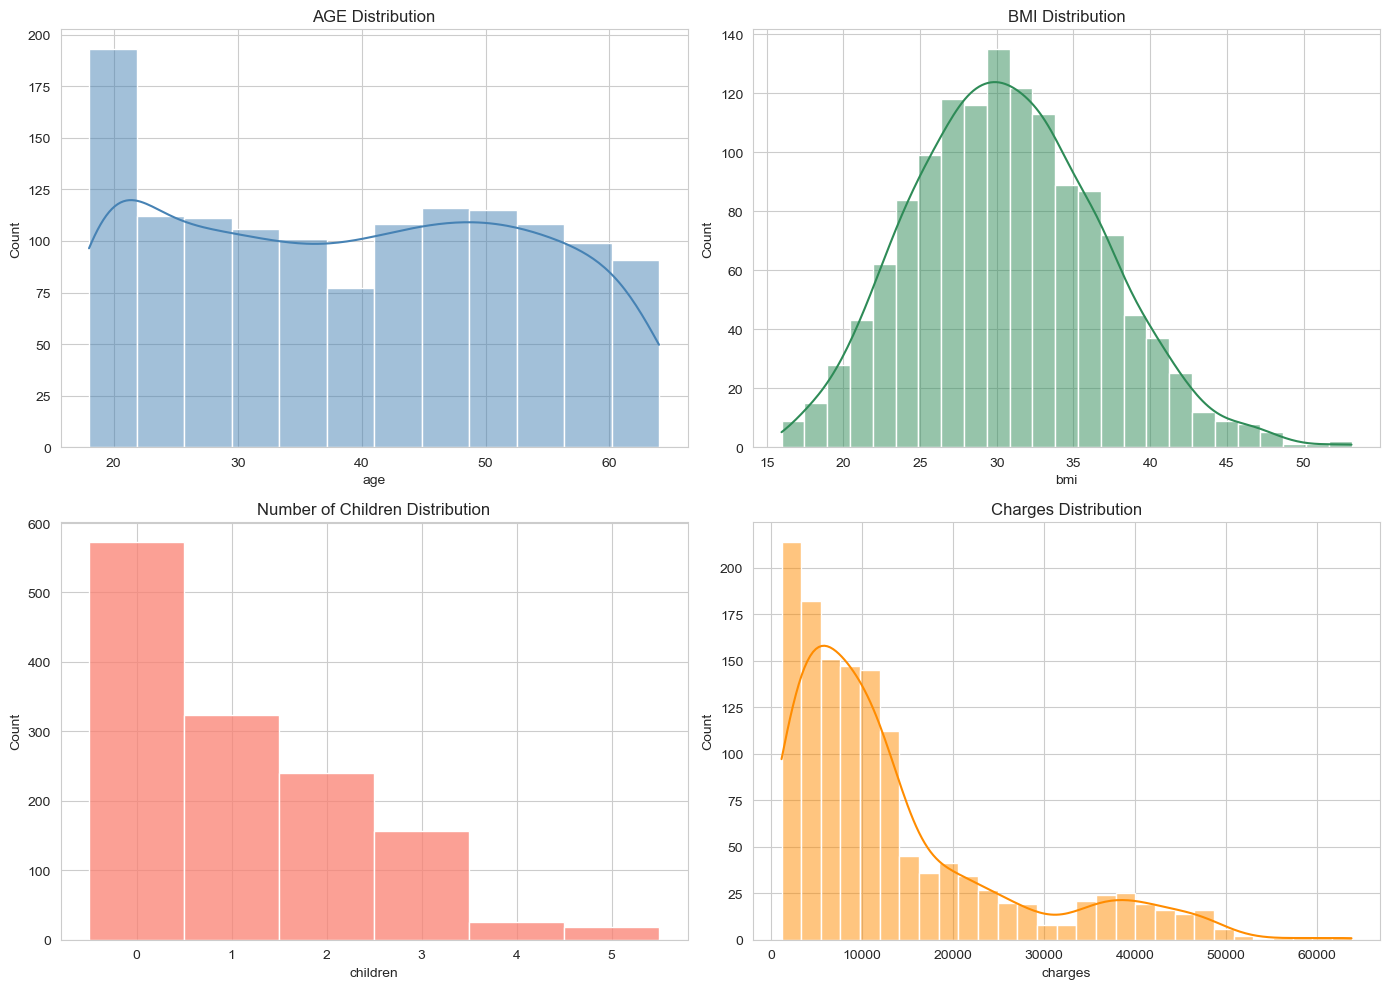

In [20]:
# Histogram for this

fig, axes = plt.subplots(2, 2, figsize = (14,10))

sns.histplot(df["age"],kde = True, ax = axes[0,0],color = "steelblue")
axes[0,0].set_title("AGE Distribution")

sns.histplot(df["bmi"],kde = True, ax = axes[0,1],color = "seagreen")
axes[0,1].set_title("BMI Distribution")

sns.histplot(df["children"],discrete = True, ax = axes[1,0],color = "salmon")
axes[1,0].set_title("Number of Children Distribution")

sns.histplot(df["charges"],kde = True, ax = axes[1,1],color = "darkorange")
axes[1,1].set_title("Charges Distribution")

plt.tight_layout()

plt.show()

In [21]:
# Outlier remove for BMI and Charge   by IQR method

for col in ["bmi" , "charges"]:
    Q1 , Q3 = df[col].quantile(0.25),df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_range = Q1 - 1.5 * IQR
    upper_range = Q3 + 1.5 * IQR
    n_outlier = ((df[col]< lower_range) | (df[col]> upper_range)).sum()

    print(f"{col}: bounds = ({lower_range:.1f},{upper_range:.1f}, outliers = {n_outlier}({n_outlier / len(df)*100:.1f}))")


bmi: bounds = (13.7,47.3, outliers = 9(0.7))
charges: bounds = (-13120.7,34524.8, outliers = 139(10.4))


In [22]:
 # check 

 df.groupby("smoker")["charges"].agg(["mean", "median", "std", "count"])

,mean,median,std,count
smoker,,,,
no,8440.660307,7345.72660,5992.973800,1063
yes,32050.231832,34456.34845,11541.547176,274


In [23]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [24]:
def bmi_category(bmi):
    if bmi < 18.5:
        return "Underweight"
    elif bmi < 25:
        return "Normal"
    elif bmi < 30:
        return "Overweight"
    else:
        return "Obese"


In [25]:
df["bmi_category"] = df["bmi"].apply(bmi_category)

In [26]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,Overweight
1,18,male,33.770,1,no,southeast,1725.55230,Obese
2,28,male,33.000,3,no,southeast,4449.46200,Obese
3,33,male,22.705,0,no,northwest,21984.47061,Normal
4,32,male,28.880,0,no,northwest,3866.85520,Overweight


In [27]:
df["bmi_category"].value_counts()

bmi_category
Obese          706
Overweight     386
Normal         225
Underweight     20
Name: count, dtype: int64

In [28]:
df.groupby("bmi_category")["charges"].mean().sort_values().round(2)

bmi_category
Underweight     8852.20
Normal         10409.34
Overweight     10987.51
Obese          15572.04
Name: charges, dtype: float64

Charges are right skewed distributed so use log transformation to convert large amount to a comaprable scale.

Skewness Transformation – Short Notes
1. Right Skewed Data (Positive Skewness)
- Tail of the distribution is towards the right.
- Most values are concentrated on the left.
- Common technique: Log Transformation.
- Example: np.log1p(x)
2. Left Skewed Data (Negative Skewness)
- Tail of the distribution is towards the left.
- Most values are concentrated on the right.
- Common technique: Reflection + Log Transformation.
- Example:x_transformed = np.log1p(x.max() + 1 - x)



NOTE :- Log Transformation handles distribution shape, whereas Normalization handles data scale.

In [29]:
df["log_charges"] = np.log1p(df["charges"])

In [30]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category,log_charges
0,19,female,27.900,0,yes,southwest,16884.92400,Overweight,9.734236
1,18,male,33.770,1,no,southeast,1725.55230,Obese,7.453882
2,28,male,33.000,3,no,southeast,4449.46200,Obese,8.400763
3,33,male,22.705,0,no,northwest,21984.47061,Normal,9.998137
4,32,male,28.880,0,no,northwest,3866.85520,Overweight,8.260455


In [31]:
print(df["charges"].skew())

1.5153909108403483


In [32]:
print(df["log_charges"].skew())

-0.08955835073325419


Encode the categorical variable

One hot encoding


In [33]:
 df_model = pd.get_dummies(
    df,
    columns = ["sex", "smoker", "region", "bmi_category"],
    drop_first = True
 )

 print(df_model.columns.to_list())

['age', 'bmi', 'children', 'charges', 'log_charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_Obese', 'bmi_category_Overweight', 'bmi_category_Underweight']


In [34]:
df_model.head()

,age,bmi,children,charges,log_charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_category_Obese,bmi_category_Overweight,bmi_category_Underweight
0,19,27.900,0,16884.92400,9.734236,False,True,False,False,True,False,True,False
1,18,33.770,1,1725.55230,7.453882,True,False,False,True,False,True,False,False
2,28,33.000,3,4449.46200,8.400763,True,False,False,True,False,True,False,False
3,33,22.705,0,21984.47061,9.998137,True,False,True,False,False,False,False,False
4,32,28.880,0,3866.85520,8.260455,True,False,True,False,False,False,True,False


In [35]:
X = df_model.drop(columns=["charges", "log_charges"])
y = df_model["log_charges"]

train test split(80 - 20)

In [36]:
X_train, X_test , y_train , y_test = train_test_split(X,y, test_size = 0.2)

In [38]:
y_test_real = np.expm1(y_test)

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators = 300, max_depth = 6, n_jobs = -1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators = 300, max_depth = 3, learning_rate= 0.05)
}

trained_models = {}
metrics_rows = []

for name , model in candidate_models.items():

    model.fit(X_train, y_train)
    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)

    r2 = r2_score(y_test_real , y_pred)
    mae = mean_absolute_error(y_test_real, y_pred)
    rmse = np.sqrt(mean_absolute_error(y_test_real, y_pred))

    trained_models[name] = model
    metrics_rows.append({"Model": name, "R2": r2 , "MAE": mae , "RMSE": rmse})

    print(f"{name} --> R2:- {r2:.3f} , MAE:- {mae:.3f} , RMSE:- {rmse:.3f}")

Linear Regression --> R2:- 0.493 , MAE:- 4454.805 , RMSE:- 66.744
Random Forest --> R2:- 0.850 , MAE:- 2161.255 , RMSE:- 46.489
Gradient Boosting --> R2:- 0.824 , MAE:- 2447.789 , RMSE:- 49.475
